# Predicting the parameter bias from a wrong n(z)

`FisherFlex.forecast` says how *precisely* a survey measures cosmology.  This notebook
uses `FisherFlex.forecast_bias` to ask the other question: if the true source n(z) is not
the one we assumed, how far off is the answer?

It uses the DESC nz-challenge task-set 1 (Cardinal, 1yr, WFD) files in this directory,
where the *truth* is known -- so we can measure the bias rather than guess at it.

In [1]:
import numpy as np
from matplotlib import pyplot as plt

import sys
import numpy.core

sys.modules["numpy._core"] = numpy.core
sys.modules["numpy._core.numeric"] = numpy.core.numeric
sys.modules["numpy._core.multiarray"] = numpy.core.multiarray

import importlib
from scipy.interpolate import interp1d
import inspect
import fisherA2Z.fisher_flex as ff
importlib.reload(ff.nzq)
ff = importlib.reload(ff)
FisherFlex = ff.FisherFlex

print("Fisher:", ff.__file__)
print("Cuantiles:", ff.nzq.__file__)
print("validate_prior_cov:", inspect.signature(ff.nzq.validate_prior_cov))

from fisherA2Z import nz_shift_stretch as nzss
import tables_io
nzq = ff.nzq  # Mismo módulo para las gráficas y Fisher.
import qp
%matplotlib inline
plt.rcParams["figure.dpi"] = 110

Fisher: /home/davidmarquez/photometric_redshifts_project/fisherA2Z/src/fisherA2Z/fisher_flex.py
Cuantiles: /home/davidmarquez/photometric_redshifts_project/fisherA2Z/src/fisherA2Z/nz_quantiles.py
validate_prior_cov: (cov, n_source, n_params=None)


### grab the central n(z) and the zgrid

In [2]:
"""
data = np.load("/home/davidmarquez/photometric_redshifts_project/yaw_bins/Results/source_year1_outliers_OFF.npz")

print("Claves:", data.files)

for key in data.files:
    array = np.asarray(data[key])
    print(
        f"{key:10s} "
        f"shape={array.shape}, "
        f"dtype={array.dtype}, "
        f"min={np.nanmin(array):.4e}, "
        f"max={np.nanmax(array):.4e}"
    )

""";

In [3]:
"""
z_grid = np.asarray(data["z_grid"])
nz_true = np.asarray(data["nz_truth"])

#nz_observed = np.asarray(data["samples"][:, 50000, :]) # Tomo solo la observación 50, 001
nz_observed = np.mean(data["samples"], axis=1) # Estoy tomando todos los samples.
samples = np.asarray(data["samples"])

n_bins, n_realizations, n_z = samples.shape

print("z_grid:", z_grid.shape)
print("nz_true:", nz_true.shape)
print("nz_observed:", nz_observed.shape)
print("samples:", samples.shape)

""";

In [4]:
"""
# INTERPOLACIÓN
# Grid original y nuevo: mismos límites
z_original = np.asarray(data["z_grid"], dtype=float)
z_grid = np.linspace(z_original[0], z_original[-1], 200)

# Distribución verdadera: (5, 40) → (5, 200)
nz_true = interp1d(
    z_original,
    data["nz_truth"],
    axis=-1,
    assume_sorted=True,
)(z_grid)

# Realizaciones originales
samples_original = data["samples"]
n_bins, n_realizations, _ = samples_original.shape

# Reservar memoria para el resultado
samples = np.empty(
    (n_bins, n_realizations, z_grid.size),
    dtype=np.float64,
)

# Interpolar por bloques para limitar la memoria temporal
batch_size = 2000

for b in range(n_bins):
    for start in range(0, n_realizations, batch_size):
        stop = min(start + batch_size, n_realizations)

        samples[b, start:stop] = interp1d(
            z_original,
            samples_original[b, start:stop],
            axis=-1,
            assume_sorted=True,
        )(z_grid)

# Recalcular el promedio sobre el grid nuevo
nz_observed = samples.mean(axis=1)
n_mean = nz_observed.copy()
nz_central = nz_observed

n_z = z_grid.size

print("z_grid:", z_grid.shape)
print("nz_true:", nz_true.shape)
print("samples:", samples.shape)
print("nz_central:", nz_central.shape)

""";

In [5]:
#np.savez_compressed("source_year1_outliers_OFF_200p.npz", z_grid=z_grid, nz_truth=nz_true, samples=samples)

In [6]:
data = np.load("source_year1_outliers_OFF_200p.npz")

z_grid = data["z_grid"]
nz_true = data["nz_truth"]
samples = data["samples"]

nz_observed = samples.mean(axis=1)

In [7]:
print("z_grid:", z_grid.shape)
print("nz_true:", nz_true.shape) # Sigue siendo el true
print("samples:", samples.shape)
print("nz_observed:", nz_observed.shape) #  samples.mean(axis=1)

z_grid: (200,)
nz_true: (5, 200)
samples: (5, 199499, 200)
nz_observed: (5, 200)


In [8]:
n_mean = samples.mean(axis=1)

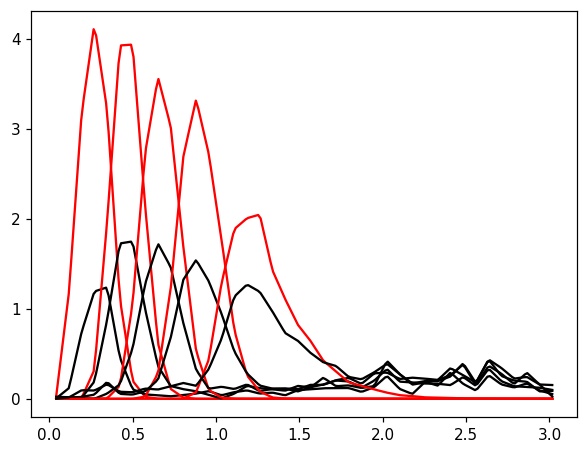

In [9]:
for i in range(5):
    plt.plot(z_grid, nz_true[i], color= 'r')
    plt.plot(z_grid, n_mean[i], color = 'k')

## Cambio de nz

In [10]:
data_nz_quantiles_true10  = np.load(
    "/home/davidmarquez/photometric_redshifts_project/eleni_new/bayesian-pipelines-cosmology/notebooks/photo-z/reconstruction_param_nz/quantiles_true10.npz", 
    allow_pickle=True
)

In [11]:
# Extraemos primero los datos originales (5, 500)

nz = data_nz_quantiles_true10["data_nz_quantiles_true10"]

x_orig = np.array([f.x for f in nz])   # (5, 500)
y_orig = np.array([f.y for f in nz])   # (5, 500)
print(x_orig.shape, y_orig.shape)

(5, 500) (5, 500)


In [12]:
# Remuestrar a (5, 200)

n_new = 200

x_new = np.empty((len(nz), n_new))
y_new = np.empty((len(nz), n_new))

for i, f in enumerate(nz):
    x_new[i] = np.linspace(f.x.min(), f.x.max(), n_new)
    y_new[i] = f(x_new[i])            # evalúa el interp1d en la malla nueva

print(x_new.shape, y_new.shape)       # (5, 200) (5, 200)

(5, 200) (5, 200)


In [13]:
nz_param = y_new
print(nz_param.shape)

(5, 200)


In [14]:
# Cambio importante

nz_central = nz_observed # el central es in mean de los samples.

In [15]:
delta_nzparam = nz_param - nz_central

In [16]:
nz_i = nz_central + delta_nzparam
print(nz_i.shape)

(5, 200)


In [17]:
n_bins, n_realizations, n_z = samples.shape

## Measure the quantile prior

Para cada realización se obtienen las ocho posiciones interiores en los niveles
`1/9,...,8/9`. La forma es `(5,8,8)`. Se utilizan todas las realizaciones; los lotes solo limitan el uso de memoria. No se carga el prior anterior de `lens_year1_outliers_ON.npz`.

In [18]:
N_QUANTILES = 25             # Niveles de probabilidad, incluidos los extremos.
N_QPARAMS = N_QUANTILES - 2     
INTERPOLATION_ORDER = 1        # 0 constante; 1 lineal; 2 cuadrática.

# Voy a reemplazar las nz_central por nz_i

levels = np.linspace(0.0, 1.0, N_QUANTILES) # Probabilidades acumuladas: [0, 0.25, 0.5, 0.75, 1].
quantile_locs = nzq.quantile_locations(z_grid, nz_i, levels)

assert quantile_locs.shape == (n_bins, N_QUANTILES)

print("Posiciones de cuantiles:", quantile_locs.shape)
print("Parámetros libres por bin:", N_QPARAMS)
# Fisher calculará el prior de forma (n_bins, N_QPARAMS, N_QPARAMS)
# a partir de samples; no se utiliza una matriz vacía como prior.

Posiciones de cuantiles: (5, 25)
Parámetros libres por bin: 23


### calculate the effective number density

In [19]:
"""
In cosmological surveys, the effective number density (\(n_{\text{eff}}\)) of galaxies with photometric redshifts is used to 
quantify the statistical power of weak gravitational lensing and large-scale structure measurements 
by accounting for measurement noise and data quality cuts.


Esta sección calcula cuántas galaxias por minuto de arco cuadrado corresponden a cada bin tomográfico. 
El resultado, neff, proporciona a Fisher la densidad de galaxias de cada bin.

"""

# Número de galaxias por bin (source_year1_outliers_OFF), obtenido de tesis maestría
N_bin1 = 8948804
N_bin2 = 11931308
N_bin3 = 18775172
N_bin4 = 28150731
N_bin5 = 32605199


# Conteos del catálogo que produjo source_year1_outliers_OFF.npz
counts = np.array([N_bin1, N_bin2, N_bin3, N_bin4, N_bin5])

# Área útil de ese catálogo -> Grados cuadrados
area_deg2 = 659 

neff = counts / (3600 * area_deg2)


print(f'number counts in bins = {counts}')
print(f'effective number density in bins = {neff}')

number counts in bins = [ 8948804 11931308 18775172 28150731 32605199]
effective number density in bins = [ 3.77204687  5.0292143   7.91399933 11.86592944 13.74355041]


### the truth

`..._nz_true_wfd.hdf5` holds the true n(z) of the same five bins, as a histogram.
`qp` puts it straight onto our grid.

In [20]:
# nz_true = qp.read('./nz_challenge_taskset_1_cardinal_1yr_nz_true_wfd.hdf5').pdf(z_grid)

mean_true = np.trapz(nz_true * z_grid, z_grid, axis=1) / np.trapz(nz_true, z_grid, axis=1) # nz_truth de niko
mean_cen = np.trapz(nz_i * z_grid, z_grid, axis=1) / np.trapz(nz_i, z_grid, axis=1) # Mean de los samples

print(f"{'bin':<5}{'<z> true':>10}{'<z> central':>13}{'difference':>12}")
for i in range(5):
    print(f"{i+1:<5}{mean_true[i]:>10.4f}{mean_cen[i]:>13.4f}{mean_true[i]-mean_cen[i]:>+12.4f}")

bin    <z> true  <z> central  difference
1        0.2740       0.6399     -0.3659
2        0.4693       0.7504     -0.2811
3        0.6704       0.8749     -0.2046
4        0.9038       1.0208     -0.1170
5        1.3003       1.2629     +0.0374


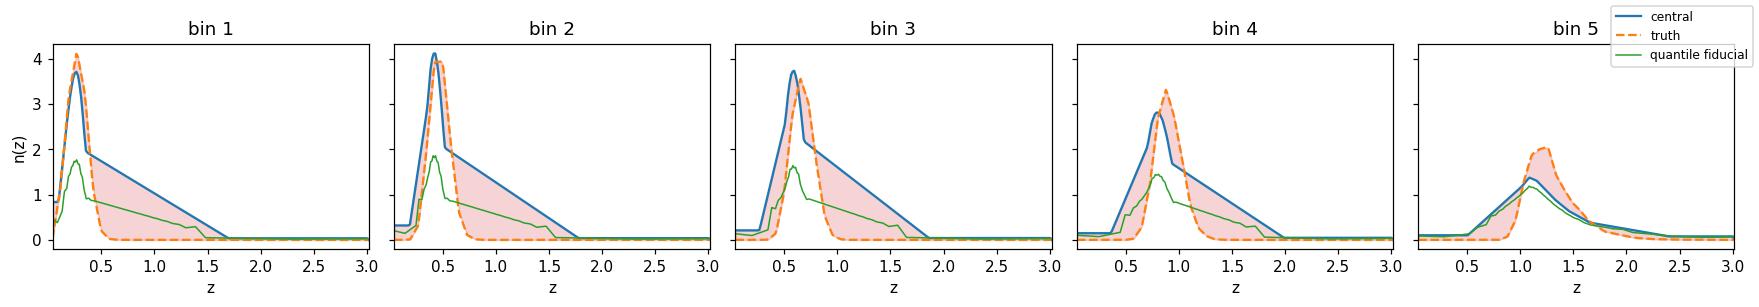

In [21]:
z_plot = np.unique(np.concatenate([np.linspace(a,b,33) for a,b in zip(z_grid[:-1],z_grid[1:])]))
fig, axes = plt.subplots(1,n_bins,figsize=(16,2.8),sharey=True,squeeze=False)
for i,ax in enumerate(axes[0]):
    ax.plot(z_grid,nz_i[i],color="C0",label="central" if i==0 else None)
    ax.plot(z_grid,nz_true[i],color="C1",ls="--",label="truth" if i==0 else None)
    nz_quant = nzq.evaluate_quantile_nz(z_plot, levels, quantile_locs[i], np.zeros(N_QPARAMS), interpolation_order=INTERPOLATION_ORDER)
    ax.plot(z_plot,nz_quant,color="C2",lw=1,label="quantile fiducial" if i==0 else None)
    ax.fill_between(z_grid,nz_i[i],nz_true[i],color="C3",alpha=0.2)
    ax.set(title=f"bin {i+1}",xlabel="z",xlim=(z_grid[0],z_grid[-1]))
axes[0,0].set_ylabel("n(z)")
fig.legend(loc="upper right",fontsize=8)
fig.tight_layout()
plt.show()

### the forecast

Same 3x2pt setup as `forecast_example.ipynb`.  The n(z) we hand it is the **central**
one -- the truth is not used here, only in the bias step below.

In [22]:
flex = FisherFlex(
    # -- the n(z) and its uncertainty ---------------------------------
    nz_source=nz_i,
    nz_realizations=samples,
    realizations_axis=1,
    z_grid=z_grid,
    photoz_prior_cov = None,
    # -- the survey ---------------------------------------------------
    neff_source=neff,                   # arcmin^-2, per tomographic bin
    fsky=0.5,
    sigma_e=0.26,                       # per-component ellipticity dispersion
    # -- the analysis -------------------------------------------------
    mode="cosmic_shear", nz_model="quantiles",
    n_quantiles=N_QUANTILES,
    quantile_interpolation_order=INTERPOLATION_ORDER
)

assert flex.n_pz_per_bin == N_QPARAMS
assert flex.pz_prior_cov.shape == (n_bins, N_QPARAMS, N_QPARAMS)
np.testing.assert_allclose(flex.quantile_locs, quantile_locs)
print("Prior de cuantiles:", flex.pz_prior_cov.shape)

#flex.compute(parallel=True, save="nzdc_y1_3x2pt.npz")
flex.compute(parallel=True)

forecast_params = dict(ell_max_cs=1800, ell_min_cs=300)
res = flex.forecast(**forecast_params)


"""
# Para fijar A0 y que no se tome en cuenta
flex.compute(parallel=True)

forecast_params = dict(ell_max_cs=1800, ell_min_cs=300)

# Fijar A0 en su valor fiducial
config = dict(forecast_params)
config["drop_params"] = ["A0"]

res = flex.forecast(**config)

s8, s8_err = res.s8()
print(f"S_8 = {s8:.4f} +/- {s8_err:.4f}")
print("FoM:", res.fom("w_0", "w_a"))"""

Prior de cuantiles: (5, 23, 23)
Computing the fiducial data vector and covariance ...


/home/davidmarquez/photometric_redshifts_project/fisherA2Z/src/fisherA2Z/fisher_flex.py:1626: UserWarning: mean quantile displacements exceed their realization scatter for ['qshift1_1', 'qshift2_1', 'qshift3_1', 'qshift4_1', 'qshift5_1', 'qshift6_1', 'qshift7_1', 'qshift9_1', 'qshift10_1', 'qshift11_1', 'qshift12_1', 'qshift13_1', 'qshift14_1', 'qshift15_1', 'qshift16_1', 'qshift17_1', 'qshift18_1', 'qshift19_1', 'qshift20_1', 'qshift21_1', 'qshift22_1', 'qshift23_1', 'qshift1_2', 'qshift2_2', 'qshift3_2', 'qshift4_2', 'qshift5_2', 'qshift6_2', 'qshift7_2', 'qshift8_2', 'qshift9_2', 'qshift11_2', 'qshift13_2', 'qshift14_2', 'qshift15_2', 'qshift16_2', 'qshift17_2', 'qshift18_2', 'qshift19_2', 'qshift20_2', 'qshift21_2', 'qshift22_2', 'qshift23_2', 'qshift1_3', 'qshift2_3', 'qshift3_3', 'qshift4_3', 'qshift5_3', 'qshift6_3', 'qshift7_3', 'qshift8_3', 'qshift9_3', 'qshift10_3', 'qshift11_3', 'qshift12_3', 'qshift13_3', 'qshift14_3', 'qshift15_3', 'qshift16_3', 'qshift17_3', 'qshift18_3',

Computing derivatives for 136 parameters (parallel) ...
Done.


'\n# Para fijar A0 y que no se tome en cuenta\nflex.compute(parallel=True)\n\nforecast_params = dict(ell_max_cs=1800, ell_min_cs=300)\n\n# Fijar A0 en su valor fiducial\nconfig = dict(forecast_params)\nconfig["drop_params"] = ["A0"]\n\nres = flex.forecast(**config)\n\ns8, s8_err = res.s8()\nprint(f"S_8 = {s8:.4f} +/- {s8_err:.4f}")\nprint("FoM:", res.fom("w_0", "w_a"))'

### predict the bias

`forecast_bias` forward-models the data vector twice -- once with the central n(z), once
with the truth -- and pushes the residual through Eq. (13) of the FisherA2Z paper,

$$f_\alpha = \mathbb{I}^{-1}\cdot\left(\frac{dC_\ell}{d\alpha}\cdot V\cdot(C_\ell^{\rm biased}-C_\ell)\right)$$

Everything `forecast()` accepts goes in `forecast_params`, so the bias is quoted against
exactly the forecast above -- same scale cuts, same priors.

In [23]:
bias = flex.forecast_bias(nz_truth=nz_true, forecast_params=forecast_params)

print(bias.summary(["omega_m", "sigma_8", "w_0", "w_a"]))

s8_fid, s8_shifted, ds8, ds8_sigma = bias.s8()
print(f"\nS_8: {s8_fid:.4f} -> {s8_shifted:.4f}  ({ds8:+.4f}, {ds8_sigma:+.2f} sigma)")

parameter         fiducial        bias  bias/sigma     shifted
omega_m             0.3156    0.029871       8.308     0.34547
sigma_8              0.831   -0.037734      -5.651     0.79327
w_0                     -1     -3.0696     -22.054     -4.0696
w_a                      0    -0.49649     -12.304    -0.49649

S_8: 0.8523 -> 0.8513  (-0.0011, -0.16 sigma)


### the bias in a 2d plane

`bias/sigma` treats each parameter on its own.  `bias_2d` marginalizes over everything
else and measures the shift against the 2x2 covariance -- the contour you actually plot.
A shift can be small in both marginal error bars and still sit outside the ellipse, if it
runs *across* the degeneracy instead of along it, so the two questions have different
answers.

In [24]:
for pair in [("omega_m", "sigma_8"), ("w_0", "w_a")]:
    print(bias.bias_2d(*pair))
    print()

bias in the (omega_m, sigma_8) plane
  omega_m           0.3156 ->     0.34547   (+8.31 sigma_1D)
  sigma_8            0.831 ->     0.79327   (-5.65 sigma_1D)
  joint: chi2 = 75.302, sqrt(chi2) = 8.68, enclosing 100.0% of the posterior
  direction: -51.6 deg;  inside 1 sigma: False;  inside 2 sigma: False

bias in the (w_0, w_a) plane
  w_0                   -1 ->     -4.0696   (-22.05 sigma_1D)
  w_a                    0 ->    -0.49649   (-12.30 sigma_1D)
  joint: chi2 = 733.470, sqrt(chi2) = 27.08, enclosing 100.0% of the posterior
  direction: -170.8 deg;  inside 1 sigma: False;  inside 2 sigma: False



In [25]:
# bias in the 2d plane

# bias in om-sigma8 plane 
print(bias.bias_2d("omega_m", "sigma_8").confidence)

# bias in wowa plane 
print(bias.bias_2d("w_0", "w_a").confidence)

1.0
1.0


### plot it

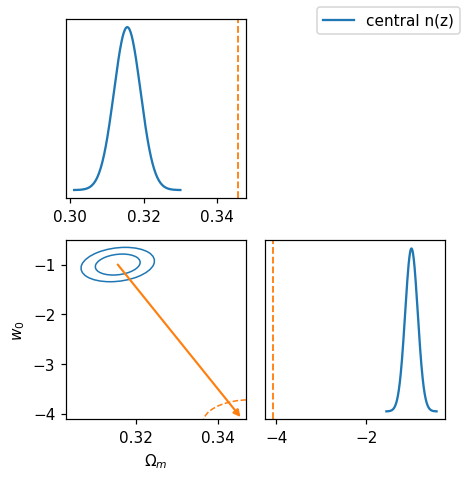

In [26]:
#params = ["omega_m", "sigma_8", "w_0", "w_a"]
params = ["omega_m", "w_0", ]


fig = res.corner(params, color="C0", label="central n(z)")
bias.corner_arrows(params, fig=fig, shifted_contour=True, color="C1")
fig.legend(loc="upper right", fontsize=10)
plt.show()

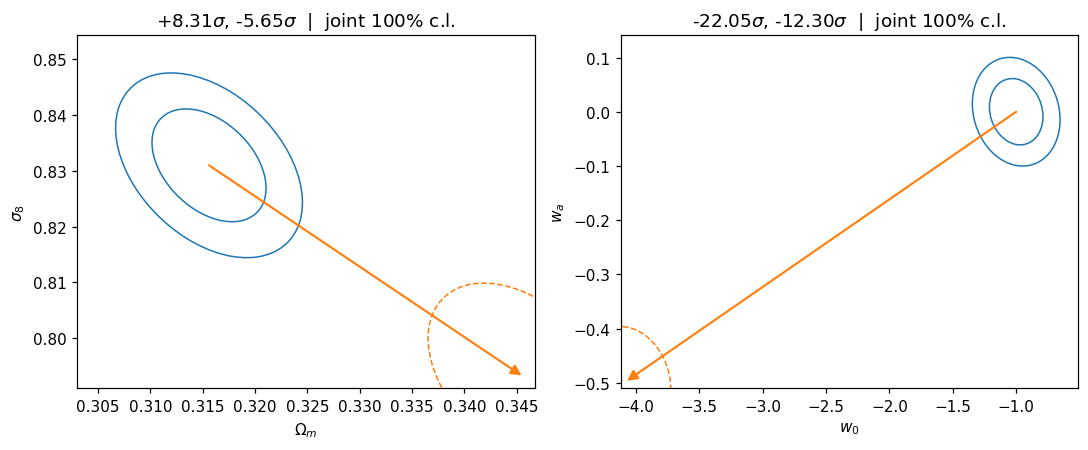

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (p1, p2) in zip(axes, [("omega_m", "sigma_8"), ("w_0", "w_a")]):
    res.contour(p1, p2, ax=ax, color="C0")
    bias.arrow(p1, p2, ax=ax, shifted_contour=True, color="C1")
    b2 = bias.bias_2d(p1, p2)
    ax.set_title(f"{bias.n_sigma(p1):+.2f}$\sigma$, {bias.n_sigma(p2):+.2f}$\sigma$"
                 f"  |  joint {b2.confidence:.0%} c.l.")
plt.tight_layout()
plt.show()

In [28]:
res = flex.forecast(**forecast_params)

fom_om_s8 = res.fom("omega_m", "sigma_8")
fom_w0_wa = res.fom("w_0", "w_a")

print(f"FoM (Omega_m, sigma_8): {fom_om_s8:.4f}")
print(f"FoM (w_0, w_a):        {fom_w0_wa:.4f}")

FoM (Omega_m, sigma_8): 45549.4440
FoM (w_0, w_a):        180.0060


In [29]:
bla=np.load("tmp.npy")

In [30]:
bla.shape

(5, 200)

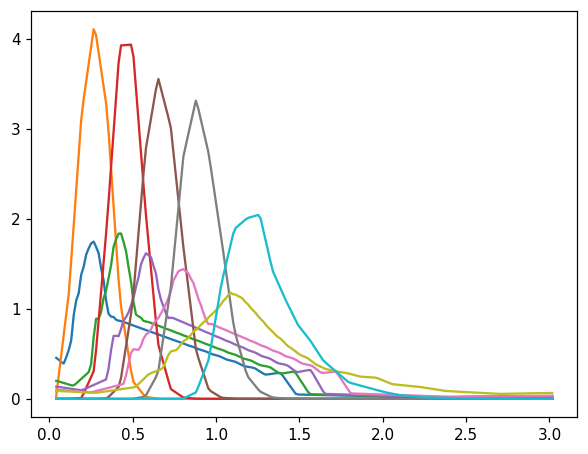

In [31]:
for i in range(5):
    plt.plot(z_grid, bla[i])
    plt.plot(z_grid, nz_true[i])